# Customer churn prediction with leakage-safe evaluation

This revision keeps preprocessing inside model pipelines and selects models using training-only cross-validation. The notebook imports `evaluate.py`, which contains the complete, readable implementation. The original data exploration is summarized in the repository README.

AI assistance was used to revise and validate the evaluation workflow.

In [1]:
from pathlib import Path
from IPython.display import display, Image
from evaluate import load_data, build_models, run_evaluation
X, y, data_path = load_data()
print(f"Customers: {len(X):,}; raw input features: {X.shape[1]}; churn rate: {y.mean():.1%}")
display(X.isna().sum().loc[lambda s: s > 0].rename("missing_values"))

Customers: 7,043; raw input features: 19; churn rate: 26.5%


TotalCharges    11
Name: missing_values, dtype: int64

## Split and preprocessing

An 80/20 stratified split is created before fitting anything. Numeric missing values use the training median; categorical missing values use the training mode. StandardScaler and OneHotEncoder are inside the pipeline. Each fold fits its own preprocessing, so validation and test rows do not influence learned preprocessing values.

Customer ID and the target are excluded from features. Inspect the pipeline below and `evaluate.py` for exact settings.

In [2]:
display(build_models(X)["Logistic Regression"])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default

## Training-only model selection

Compare a majority baseline and three classifiers with five stratified folds. Choose highest mean average precision (F1 tie-break), then evaluate only the selected pipeline on the holdout using a fixed 0.50 decision threshold. Average precision is not the same as precision at that threshold.

In [3]:
cv_results, holdout, metadata = run_evaluation()
display(cv_results.round(4))

Cross-validating: Majority baseline


Cross-validating: Logistic Regression


Cross-validating: Random Forest


Cross-validating: Balanced Random Forest


{
  "selected_model": "Logistic Regression",
  "decision_threshold": 0.5,
  "accuracy": 0.8055358410220014,
  "precision": 0.6572327044025157,
  "recall": 0.5588235294117647,
  "f1": 0.6040462427745664,
  "average_precision": 0.6346261175304457,
  "roc_auc": 0.8420677361853834,
  "true_negatives": 926,
  "false_positives": 109,
  "false_negatives": 165,
  "true_positives": 209
}


,model,average_precision_mean,average_precision_std,roc_auc_mean,roc_auc_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std
0,Majority baseline,0.2654,0.0001,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,Logistic Regression,0.6615,0.0214,0.8461,0.0140,0.6555,0.0327,0.5438,0.0457,0.5938,0.0341
2,Random Forest,0.6164,0.0316,0.8241,0.0131,0.6316,0.0389,0.4763,0.0346,0.5427,0.0337
3,Balanced Random Forest,0.6221,0.0324,0.8282,0.0141,0.5812,0.0188,0.6475,0.0355,0.6124,0.0249


## Holdout results and checks

Selected model: Logistic Regression
Precision: 65.7%; recall: 55.9%; ROC AUC: 0.842


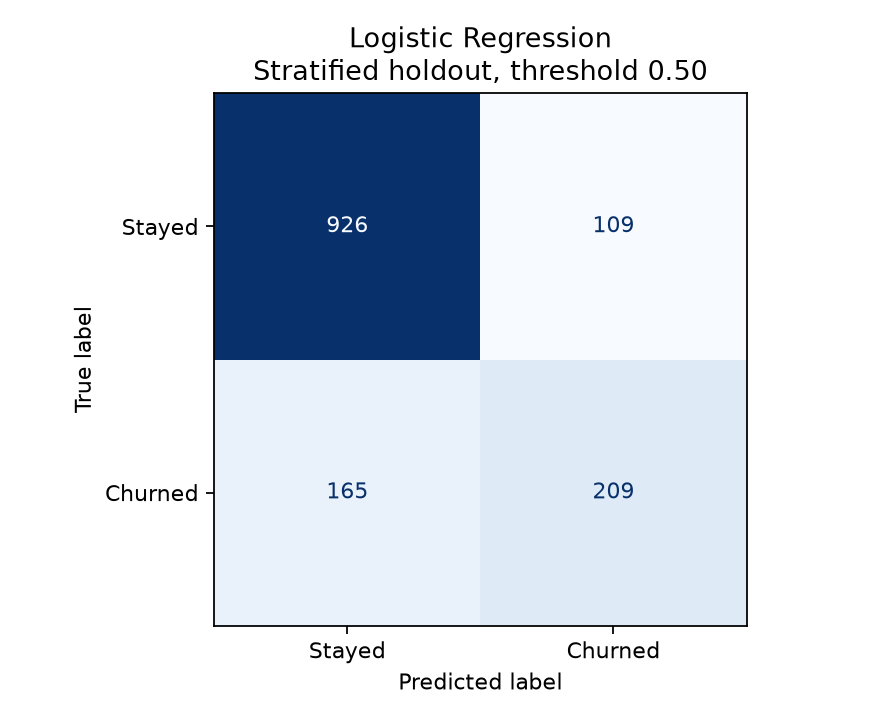

Verification: unique customers; disjoint stratified train/test; disjoint CV folds within training; target and ID excluded; imputer fitted on training medians; scaler fitted on training rows only


In [4]:
print("Selected model:", holdout["selected_model"])
print(f"Precision: {holdout['precision']:.1%}; recall: {holdout['recall']:.1%}; ROC AUC: {holdout['roc_auc']:.3f}")
display(Image(filename="results/confusion_matrix.png"))
print("Verification:", "; ".join(metadata["checks"]))

## Interpretation and limitations

Logistic Regression wins on the chosen cross-validation ranking metric. The balanced Random Forest offers higher training-CV recall with more false positives. No retention costs or intervention outcomes are available, so neither model establishes financial benefit.

The previous results are superseded, not directly comparable: missing-value handling, split stratification and preprocessing changed. This is a benchmark dataset explored in the earlier project, not independent external validation. A recall-focused threshold could be selected later using training-only out-of-fold predictions; the test set must not guide that choice.